# 🏙️ Dubai Real Estate – End to End ML Project
**Data:** Dubai Land Department transactions (Jan – Nov 2026)

**Is project mein 3 kaam hain:**
1. **Regression** – property ka *price per sq.m* predict karna (Linear Regression, Decision Tree, Random Forest)
2. **Classification** – deal *"Good Deal"* (peers se sasti) hai ya nahi (Logistic Regression, Decision Tree, Random Forest) → Accuracy, Precision, Recall
3. **Clustering** – areas ko groups mein todna + investment score (K-Means)

Code easy hai: pandas + numpy + seaborn, bina for-loop ke. Har line ke baad Hinglish comment hai.

## 1. Imports 

In [1]:
import numpy as np                                                    # numbers aur maths ke liye
import pandas as pd                                                   # data table (DataFrame) ke liye
import matplotlib.pyplot as plt                                       # charts ka base library
import seaborn as sns                                                 # sundar charts ke liye
import joblib, os                                                     # model save karne aur folder banane ke liye

from sklearn.model_selection import train_test_split, RandomizedSearchCV  # train-test split aur best settings dhoondhne ke liye
from sklearn.linear_model import LinearRegression, LogisticRegression # linear models
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier # decision tree models
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier # random forest models
from sklearn.cluster import KMeans                                    # clustering model
from sklearn.metrics import (r2_score, accuracy_score, precision_score, # model ko naapne ke metrics
                             recall_score, f1_score, classification_report, confusion_matrix, silhouette_score)


In [2]:
sns.set_theme(style="whitegrid", palette="deep")                      # seaborn ka default look set karo
pd.set_option("display.width", 200)                                   # table ki width badhao
pd.set_option("display.max_columns", 30)                              # zyada columns dikhao
os.makedirs("models", exist_ok=True)                                  # models ke liye folder banao

## Data load

In [3]:
df = pd.read_csv("Dubai_Realstate_transactions-2026-11-07.csv")       # CSV file padho

In [4]:
df.columns

Index(['TRANSACTION_NUMBER', 'INSTANCE_DATE', 'GROUP_EN', 'PROCEDURE_EN', 'IS_OFFPLAN_EN', 'IS_FREE_HOLD_EN', 'USAGE_EN', 'AREA_EN', 'PROP_TYPE_EN', 'PROP_SB_TYPE_EN', 'TRANS_VALUE',
       'PROCEDURE_AREA', 'ACTUAL_AREA', 'ROOMS_EN', 'PARKING', 'NEAREST_METRO_EN', 'NEAREST_MALL_EN', 'NEAREST_LANDMARK_EN', 'TOTAL_BUYER', 'TOTAL_SELLER', 'MASTER_PROJECT_EN', 'PROJECT_EN'],
      dtype='str')

In [5]:
df["date"] = pd.to_datetime(df["INSTANCE_DATE"], format="%d-%m-%Y %H:%M") # date text ko asli date banao

In [6]:
df.shape

(186662, 23)

In [7]:
df.head()

,TRANSACTION_NUMBER,INSTANCE_DATE,GROUP_EN,PROCEDURE_EN,IS_OFFPLAN_EN,IS_FREE_HOLD_EN,USAGE_EN,AREA_EN,PROP_TYPE_EN,PROP_SB_TYPE_EN,TRANS_VALUE,PROCEDURE_AREA,ACTUAL_AREA,ROOMS_EN,PARKING,NEAREST_METRO_EN,NEAREST_MALL_EN,NEAREST_LANDMARK_EN,TOTAL_BUYER,TOTAL_SELLER,MASTER_PROJECT_EN,PROJECT_EN,date
0,101-10-2026,01-07-2026 16:00,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,BUSINESS BAY,Unit,Flat,1699451.22,99.32,99.32,1 B/R,1,Buj Khalifa Dubai Mall Metro Station,Dubai Mall,Downtown Dubai,0,0,NaN,THE CRESTMARK,2026-07-01 16:00:00
1,101-10-2026,01-07-2026 16:00,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,BUSINESS BAY,Unit,Flat,1699451.22,46.17,46.17,Studio,1,Buj Khalifa Dubai Mall Metro Station,Dubai Mall,Downtown Dubai,0,0,NaN,THE CRESTMARK,2026-07-01 16:00:00
2,101-10-2026,01-07-2026 16:00,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,BUSINESS BAY,Unit,Flat,1699451.22,46.15,46.15,Studio,1,Buj Khalifa Dubai Mall Metro Station,Dubai Mall,Downtown Dubai,0,0,NaN,THE CRESTMARK,2026-07-01 16:00:00
3,101-10-2026,01-07-2026 16:00,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,BUSINESS BAY,Unit,Flat,1699451.22,91.81,91.81,1 B/R,1,Buj Khalifa Dubai Mall Metro Station,Dubai Mall,Downtown Dubai,0,0,NaN,THE CRESTMARK,2026-07-01 16:00:00
4,101-11-2026,01-07-2026 16:29,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,Palm Deira,Unit,Shop,6608107.80,417.91,417.91,NaN,6,NaN,NaN,NaN,0,0,NaN,ELLINGTON SANDS I,2026-07-01 16:29:00


## 2. Data Cleaning
- Sirf **asli buy/sell deals** (mortgage, gift, grant nahi)
- Sirf **residential Flat / Villa / Hotel Apartment**
- Galat prices (typo / bulk deals) hata do: price per sq.m ka bottom 1% aur top 1%

In [8]:
df = df[df["PROCEDURE_EN"].isin(["Sale", "Sell - Pre registration", "Delayed Sell"])]  # sirf buy/sell deals rakho
df = df[df["PROP_SB_TYPE_EN"].isin(["Flat", "Villa", "Hotel Apartment"]) & (df["USAGE_EN"] == "Residential")]  # sirf residential
df = df[df["ACTUAL_AREA"].between(15, 1000) & (df["TRANS_VALUE"] > 0)]  # bahut chhoti/badi area aur zero price hatao
df = df.drop_duplicates("TRANSACTION_NUMBER")                         # duplicate transactions hatao

In [9]:
df["ppsm"] = df["TRANS_VALUE"] / df["ACTUAL_AREA"]                    # price per sq.m banao (yahi hamara target hai)
low, high = df["ppsm"].quantile([0.01, 0.99])                         # bottom 1% aur top 1% ki limit nikalo
df = df[df["ppsm"].between(low, high)].copy()                         # extreme prices hata do
print("Clean rows:", len(df))                                         # kitni rows bachi dikhao
df["ppsm"].describe().round(0)                                        # price per sq.m ka summary

Clean rows: 114069


count    114069.0
mean      20134.0
std        7382.0
min        6176.0
25%       15232.0
50%       18555.0
75%       23424.0
max       48383.0
Name: ppsm, dtype: float64

## 3. Feature Engineering

Naye columns aur missing values

In [10]:
df["log_area"]    = np.log(df["ACTUAL_AREA"])                         # size ka log (skew kam karne ke liye)
df["month_idx"]   = (df["date"] - pd.Timestamp("2026-01-01")).dt.days / 30.4  # kitne mahine beete (time feature)
df["has_parking"] = df["PARKING"].notna().astype(int)                 # parking hai to 1, nahi to 0
df["month"]       = df["date"].dt.to_period("M").astype(str)          # month ka naam (chart ke liye)

df["ROOMS_EN"]   = df["ROOMS_EN"].fillna("Unknown")                   # missing rooms ko 'Unknown' bharo
df["PROJECT_EN"] = df["PROJECT_EN"].fillna("Unknown")                 # missing project ko 'Unknown' bharo
near = ["NEAREST_METRO_EN", "NEAREST_MALL_EN", "NEAREST_LANDMARK_EN"] # nearby places ke columns
df[near] = df[near].fillna("None")                                    # missing nearby ko 'None' bharo

Cell 2 – Rare projects aur peer features

In [11]:
project_count = df["PROJECT_EN"].map(df["PROJECT_EN"].value_counts()) # har row ke project ki sales count
df["PROJECT_EN"] = df["PROJECT_EN"].where(project_count >= 50, "Other") # chhote projects ko 'Other' bana do

peer = ["AREA_EN", "PROP_SB_TYPE_EN", "ROOMS_EN"]                     # peer group = same area + type + rooms
peer_area = df.groupby(peer)["ACTUAL_AREA"].transform("median")       # peer group ki median size
df["size_vs_peer"] = (df["ACTUAL_AREA"] / peer_area).clip(0, 5)       # unit peers se kitni badi/chhoti hai
proj_area = df.groupby("PROJECT_EN")["ACTUAL_AREA"].transform("median") # project ki median size
df["size_vs_project"] = (df["ACTUAL_AREA"] / proj_area).clip(0, 5)    # unit project mein kitni badi/chhoti hai
df["peer_count"] = np.log(df.groupby(peer)["ppsm"].transform("size")) # peer group mein kitni deals (popularity)

Models ke liye encoding

In [12]:
cat_cols = ["AREA_EN", "PROJECT_EN", "PROP_SB_TYPE_EN", "ROOMS_EN", "IS_OFFPLAN_EN",
            "IS_FREE_HOLD_EN", "NEAREST_METRO_EN", "NEAREST_MALL_EN", "NEAREST_LANDMARK_EN"]  # text wale columns
num_cols = ["log_area", "month_idx", "has_parking", "size_vs_peer", "size_vs_project", "peer_count"]  # number wale columns

X_tree = df[cat_cols].apply(lambda s: s.astype("category").cat.codes) # trees ke liye: text ko numbers (codes) mein badlo
X_tree[num_cols] = df[num_cols]                                       # number columns saath jodo

X_lin = pd.get_dummies(df[cat_cols], dtype="float32")                 # linear models ke liye: one-hot encoding
X_lin[num_cols] = ((df[num_cols] - df[num_cols].mean()) / df[num_cols].std()).astype("float32")  # numbers ko scale karo

print("Tree features:", X_tree.shape, "| Linear features:", X_lin.shape)  # dono tables ka size

Tree features: (114069, 15) | Linear features: (114069, 688)


## 4. EDA – data ko samjho (seaborn charts)

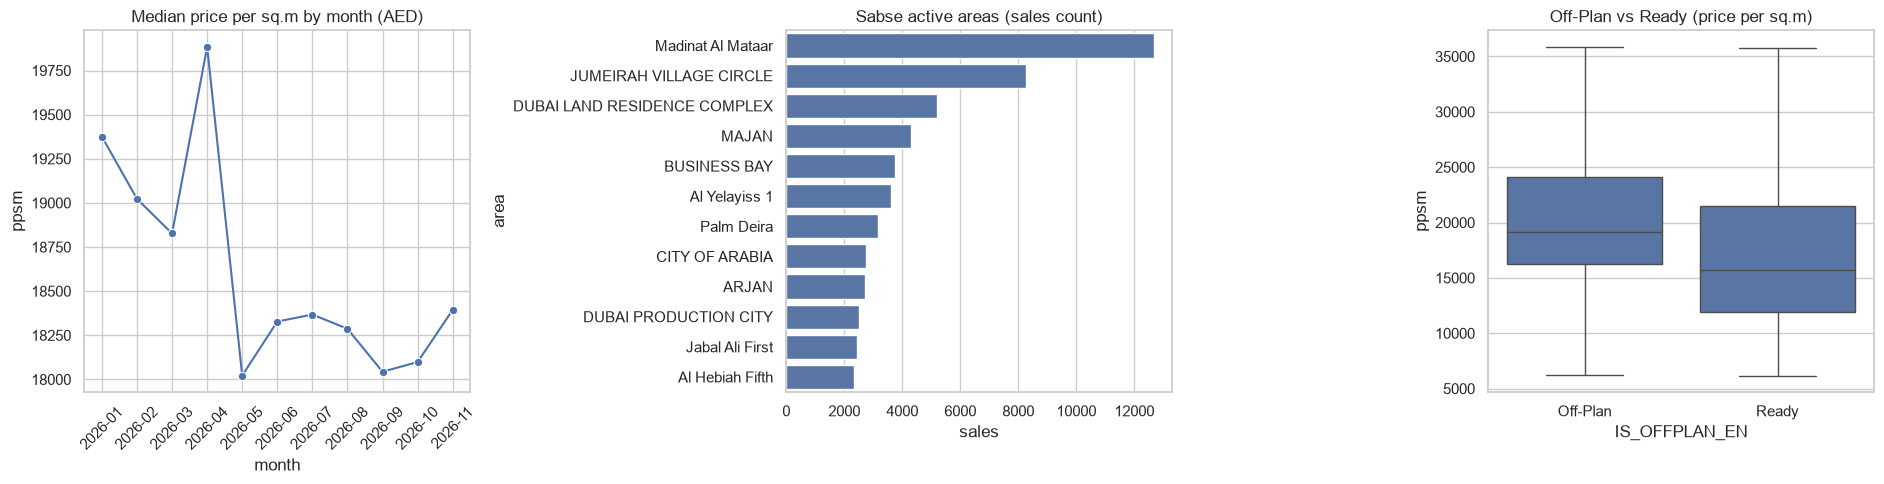

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))                         # 1 row mein 3 charts ka canvas

monthly = df.groupby("month", as_index=False)["ppsm"].median()        # mahine ke hisaab se median price
sns.lineplot(data=monthly, x="month", y="ppsm", marker="o", ax=ax[0]) # monthly price trend line chart
ax[0].set_title("Median price per sq.m by month (AED)")               # chart ka title
ax[0].tick_params(axis="x", rotation=45)                              # month labels tirche karo

top_areas = df["AREA_EN"].value_counts().head(12).reset_index()       # sabse active 12 areas
top_areas.columns = ["area", "sales"]                                 # columns ka naam rakho
sns.barplot(data=top_areas, y="area", x="sales", ax=ax[1])            # areas ka bar chart
ax[1].set_title("Sabse active areas (sales count)")                   # chart ka title

sns.boxplot(data=df, x="IS_OFFPLAN_EN", y="ppsm", showfliers=False, ax=ax[2]) # off-plan vs ready box plot
ax[2].set_title("Off-Plan vs Ready (price per sq.m)")                 # chart ka title
plt.tight_layout(); plt.show()                                        # charts dikhao 

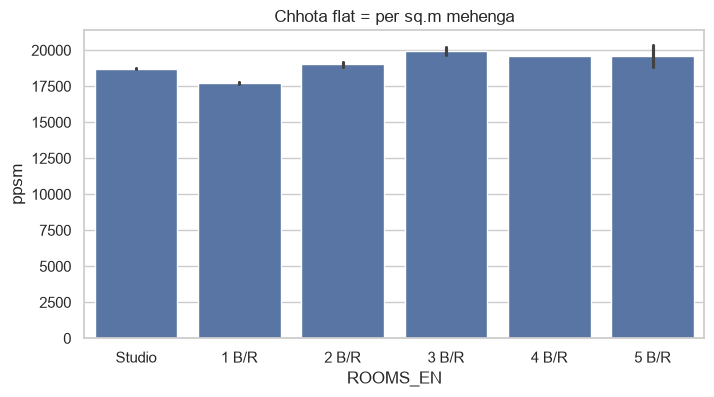

In [14]:
rooms_order = ["Studio", "1 B/R", "2 B/R", "3 B/R", "4 B/R", "5 B/R"] # rooms ka sahi order
plt.figure(figsize=(8, 4))                                            # naya chart canvas
sns.barplot(data=df[df["ROOMS_EN"].isin(rooms_order)], x="ROOMS_EN", y="ppsm", order=rooms_order, estimator=np.median)  # rooms vs median price
plt.title("Chhota flat = per sq.m mehenga"); plt.show()               # title lagao aur dikhao

## 5. Train / Test split
`train_test_split` se data ko 2 hisson mein baanto:
- **Train (90%)** – model isse seekhta hai
- **Test (10%)** – model ne ye kabhi dekha nahi, isse asli accuracy naapte hain

`shuffle=False` ka matlab: data date ke order mein hi kata jayega, yani **purani deals = train, sabse nayi deals (Oct–Nov) = test**. Real life jaisa: past se seekho, future pe test karo.

In [15]:
y  = np.log(df["ppsm"])                                               # regression target (price per sq.m ka log)

train_idx, test_idx = train_test_split(df.index, test_size=0.1, shuffle=False)  # 90% train, 10% test (date order mein)

X_tree_train, X_tree_test = X_tree.loc[train_idx], X_tree.loc[test_idx]  # trees ke liye features split
X_lin_train,  X_lin_test  = X_lin.loc[train_idx],  X_lin.loc[test_idx]   # linear models ke liye features split
y_train, y_test = y.loc[train_idx], y.loc[test_idx]                   # target split

print("Train:", len(train_idx), "| Test:", len(test_idx))             # dono ki rows count
print("Test period:", df.loc[test_idx, "date"].min().date(), "to", df.loc[test_idx, "date"].max().date())  # test kis date se kab tak

Train: 102662 | Test: 11407
Test period: 2026-01-02 to 2026-11-07


## 6. REGRESSION – Price per sq.m predict karna
Target ko **log** mein lete hain (prices skewed hote hain, isse model better seekhta hai).
Metrics: **R²** (1 ke jitna paas utna accha), **Median error %** (average galti), **Within 20%** (kitni deals 20% ke andar sahi).

In [16]:
def reg_score(name, pred_log):                                        # regression ko naapne wala function
    pred, actual = np.exp(pred_log), df.loc[test_idx, "ppsm"]          # log se wapas asli price mein
    err = (pred - actual).abs() / actual                              # har deal ki % galti
    return {"Model": name, "R2": round(r2_score(y_test, pred_log), 3), # R2 score
            "Median error %": round(100 * err.median(), 1),           # beech ki galti %
            "Within 20% (%)": round(100 * (err <= 0.2).mean(), 1)}    # kitni deals 20% ke andar

lr = LinearRegression().fit(X_lin_train, y_train)                 # Linear Regression train karo
dt = DecisionTreeRegressor(min_samples_leaf=10, random_state=0).fit(X_tree_train, y_train)  # Decision Tree train karo

pd.DataFrame([reg_score("Linear Regression", lr.predict(X_lin_test)),   # LR ka score
              reg_score("Decision Tree", dt.predict(X_tree_test))])     # DT ka score

,Model,R2,Median error %,Within 20% (%)
0,Linear Regression,0.724,11.7,71.5
1,Decision Tree,0.694,10.9,72.8


### Random Forest ko tune karo (best settings dhoondho)

In [20]:
X_small = X_tree_train.sample(30000, random_state=0)                  # tuning fast rakhne ke liye 30k rows ka sample

params = {"n_estimators": [80, 120], "min_samples_leaf": [3, 5, 8],   # kitne trees aur leaf size
          "max_features": [0.4, 0.6, 0.8], "max_depth": [None, 25]}   # har tree kitne features dekhe aur kitna gehra ho

search = RandomizedSearchCV(RandomForestRegressor(n_jobs=-1, random_state=0), params,  # random search setup
                            n_iter=8, cv=3, scoring="r2", random_state=0)              # 8 combinations, 3-fold CV
search.fit(X_small, y_train.loc[X_small.index])                         # search chalao
print("Best params:", search.best_params_, "| CV R2:", round(search.best_score_, 3))  # best settings dikhao

Best params: {'n_estimators': 120, 'min_samples_leaf': 3, 'max_features': 0.8, 'max_depth': 25} | CV R2: 0.859


In [28]:
rf_best = RandomForestRegressor(**search.best_params_, n_jobs=-1, random_state=0).fit(X_tree_train, y_train)  # best settings se poora train

reg_results = pd.DataFrame([reg_score("Linear Regression", lr.predict(X_lin_test)),   # LR score
                            reg_score("Decision Tree", dt.predict(X_tree_test)),      # DT score
                            reg_score("Random Forest (tuned)", rf_best.predict(X_tree_test))])  # RF score
reg_results                                                           # comparison table dikhao

,Model,R2,Median error %,Within 20% (%)
0,Linear Regression,0.724,11.7,71.5
1,Decision Tree,0.694,10.9,72.8
2,Random Forest (tuned),0.777,9.2,78.9


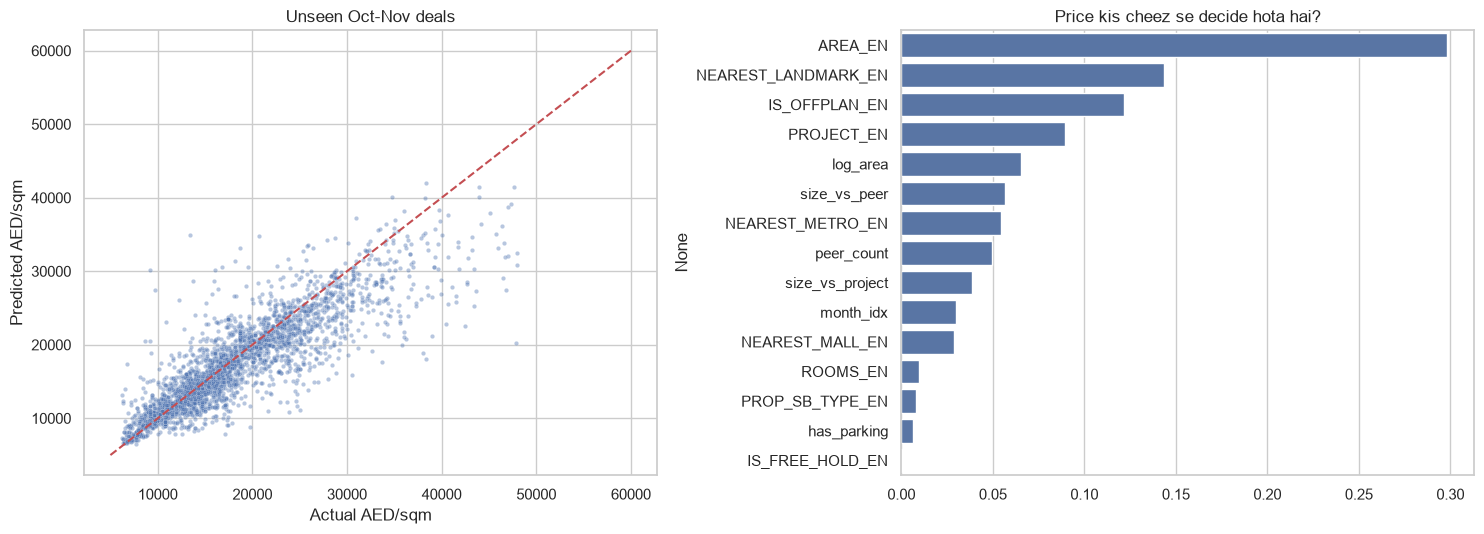

In [35]:
pred_test = np.exp(rf_best.predict(X_tree_test))                  # test ki predicted price
actual_test = df.loc[test_idx, "ppsm"].values                          # test ki asli price
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))                       # 2 charts ka canvas

pts = np.random.RandomState(0).choice(len(actual_test), 3000, replace=False)  # 3000 random points chuno
sns.scatterplot(x=actual_test[pts], y=pred_test[pts], s=10, alpha=0.4, ax=ax[0])  # actual vs predicted scatter
ax[0].plot([5000, 60000], [5000, 60000], "r--")                       # perfect prediction ki red line
ax[0].set(xlabel="Actual AED/sqm", ylabel="Predicted AED/sqm", title="Unseen Oct-Nov deals")  # labels aur title

imp = pd.Series(rf_best.feature_importances_, index=X_tree.columns).sort_values(ascending=False)  # feature importance
sns.barplot(x=imp.values, y=imp.index, ax=ax[1])                      # importance ka bar chart
ax[1].set_title("Price kis cheez se decide hota hai?")                # chart ka title
plt.tight_layout(); plt.show()                                        # charts dikhao

## 7. CLASSIFICATION – "Good Deal" detector
**Good Deal = 1** agar deal ka price/sq.m uske **peers (same area + type + rooms) ke median se 10% ya zyada sasta** ho.

- **Precision** – model ne jise "Good Deal" bola, usme se kitne sach mein good the
- **Recall** – asli good deals mein se model ne kitne pakde

In [37]:
peer_median = df.groupby(peer)['ppsm'].transform('median')
df['good_deal'] = (df['ppsm'] <= 0.90 * peer_median).astype(int)
yc = df['good_deal']
yc_train,yc_test = yc.loc[train_idx], yc.loc[test_idx]

In [ ]:
peer_median = df.groupby(peer)["ppsm"].transform("median")            # peers ka median price/sqm
df["good_deal"] = (df["ppsm"] <= 0.90 * peer_median).astype(int)      # 10% sasta = Good Deal (1), warna 0
yc = df["good_deal"]                                                  # classification ka target
yc_train, yc_test = yc.loc[train_idx], yc.loc[test_idx]              # wahi train/test split use karo
print("Good deal share:", round(yc.mean() * 100, 1), "%")             # kitne % deals good hain

plt.figure(figsize=(4, 3.5))                                          # chhota chart canvas
sns.countplot(x=yc, hue=yc, legend=False)                             # class balance dikhao
plt.title("0 = Normal, 1 = Good Deal"); plt.show()                    # title aur show